In [67]:

import pandas as pd

# Load the pharmaceutical sales dataset
df = pd.read_csv("salesweekly.csv")

# Display the first five rows
df.head()


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,1/5/2014,14.00,11.67,21.3,185.95,41.0,0.0,32.0,7.0
1,1/12/2014,29.33,12.68,37.9,190.70,88.0,5.0,21.0,7.2
2,1/19/2014,30.67,26.34,45.9,218.40,80.0,8.0,29.0,12.0
3,1/26/2014,34.00,32.37,31.5,179.60,80.0,8.0,23.0,10.0
4,2/2/2014,31.02,23.35,20.7,159.88,84.0,12.0,29.0,12.0


In [68]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (302, 9)

Column names:
['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   datum   302 non-null    str    
 1   M01AB   302 non-null    float64
 2   M01AE   302 non-null    float64
 3   N02BA   302 non-null    float64
 4   N02BE   302 non-null    float64
 5   N05B    302 non-null    float64
 6   N05C    302 non-null    float64
 7   R03     302 non-null    float64
 8   R06     302 non-null    float64
dtypes: float64(8), str(1)
memory usage: 24.0 KB

Missing values:
datum    0
M01AB    0
M01AE    0
N02BA    0
N02BE    0
N05B     0
N05C     0
R03      0
R06      0
dtype: int64


In [69]:

# Convert the date column into datetime format
df["datum"] = pd.to_datetime(df["datum"], format="%m/%d/%Y")

# Check the data types after conversion
print(df.dtypes)

# Display the first five dates
print("\nFirst five dates:")
print(df["datum"].head())


datum    datetime64[us]
M01AB           float64
M01AE           float64
N02BA           float64
N02BE           float64
N05B            float64
N05C            float64
R03             float64
R06             float64
dtype: object

First five dates:
0   2014-01-05
1   2014-01-12
2   2014-01-19
3   2014-01-26
4   2014-02-02
Name: datum, dtype: datetime64[us]


In [70]:

# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check the date range
print("\nFirst date:", df["datum"].min())
print("Last date:", df["datum"].max())


Missing values:
datum    0
M01AB    0
M01AE    0
N02BA    0
N02BE    0
N05B     0
N05C     0
R03      0
R06      0
dtype: int64

Number of duplicate rows: 0

First date: 2014-01-05 00:00:00
Last date: 2019-10-13 00:00:00


In [71]:

# Generate descriptive statistics for all sales columns
sales_columns = df.columns.drop("datum")

df[sales_columns].describe().round(2)


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
count,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00
mean,35.10,27.17,27.06,208.63,61.74,4.14,38.44,20.22
std,8.62,7.04,8.09,76.07,22.44,3.13,22.90,11.38
min,7.67,6.24,3.50,86.25,18.00,0.00,2.00,1.00
25%,29.39,22.39,21.30,149.30,47.00,2.00,21.00,11.48
50%,34.56,26.79,26.50,198.30,57.00,3.98,35.00,17.50
75%,40.17,31.05,32.48,252.47,71.00,6.00,51.00,26.00
max,65.33,53.57,60.12,546.90,154.00,17.00,131.00,65.00


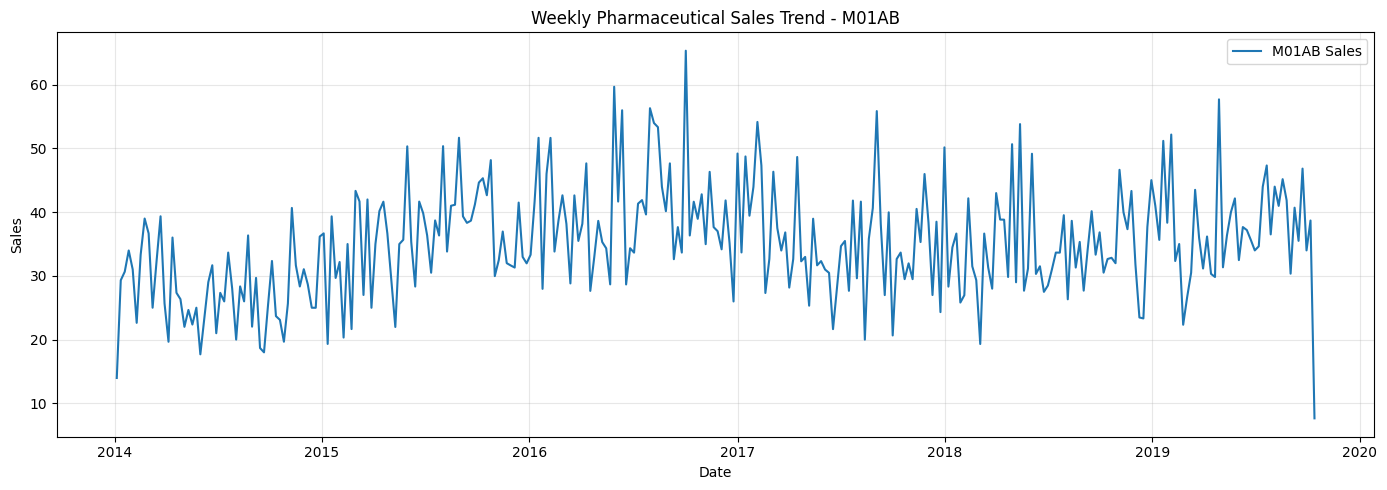

In [72]:

import matplotlib.pyplot as plt

# Plot weekly sales for the M01AB category
plt.figure(figsize=(14, 5))

plt.plot(df["datum"], df["M01AB"], label="M01AB Sales")

plt.title("Weekly Pharmaceutical Sales Trend - M01AB")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


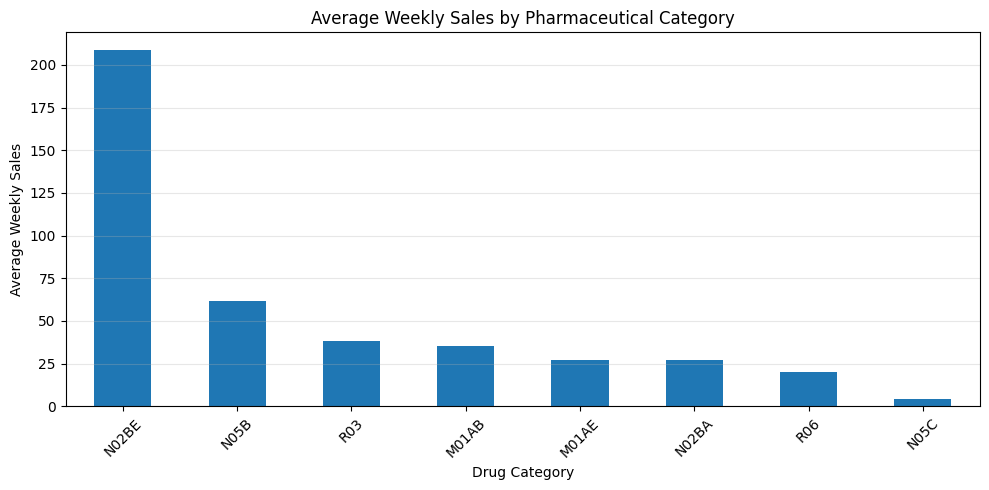

In [73]:

import matplotlib.pyplot as plt

# Calculate average sales for each category
sales_columns = df.columns.drop("datum")
average_sales = df[sales_columns].mean().sort_values(ascending=False)

# Plot average sales by category
plt.figure(figsize=(10, 5))

average_sales.plot(kind="bar")

plt.title("Average Weekly Sales by Pharmaceutical Category")
plt.xlabel("Drug Category")
plt.ylabel("Average Weekly Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


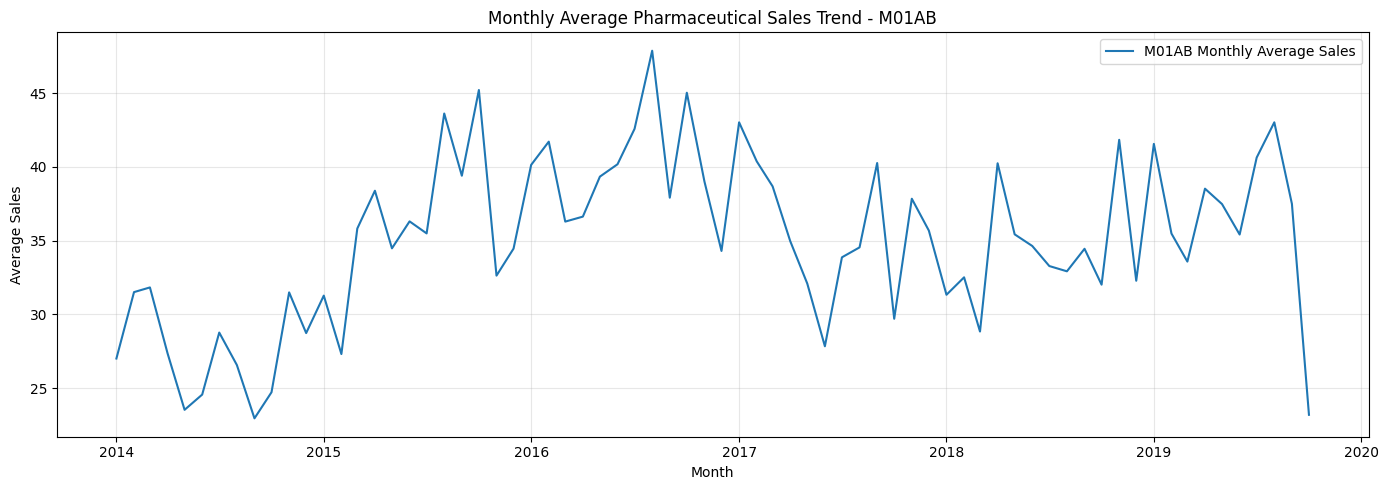

In [74]:

import matplotlib.pyplot as plt

# Calculate monthly average sales for each category
monthly_sales = (
    df.set_index("datum")
      .resample("MS")
      .mean(numeric_only=True)
)

# Plot monthly sales for M01AB
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales["M01AB"],
    label="M01AB Monthly Average Sales"
)

plt.title("Monthly Average Pharmaceutical Sales Trend - M01AB")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


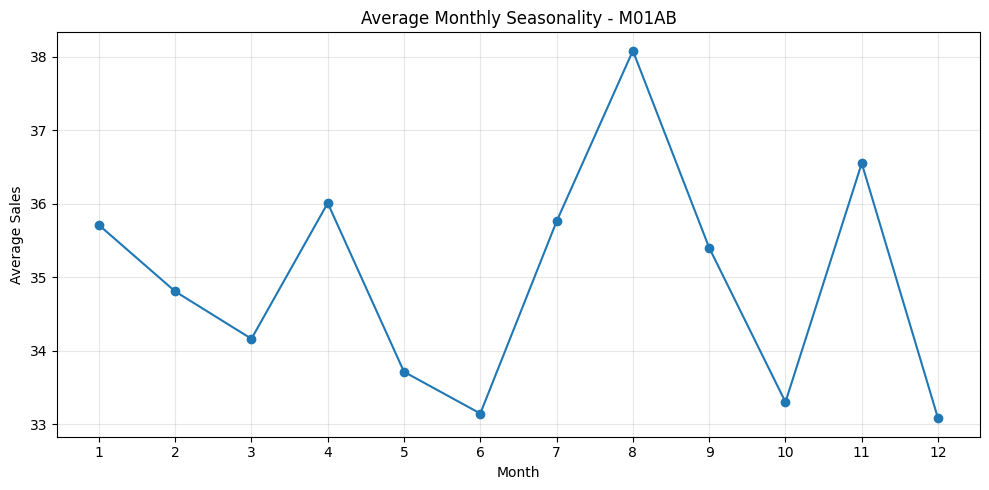

In [75]:

import matplotlib.pyplot as plt

# Calculate average sales for each calendar month
seasonal_sales = monthly_sales.groupby(
    monthly_sales.index.month
).mean()

# Plot the average sales pattern across the 12 months
plt.figure(figsize=(10, 5))

plt.plot(
    seasonal_sales.index,
    seasonal_sales["M01AB"],
    marker="o"
)

plt.title("Average Monthly Seasonality - M01AB")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [76]:

# Create a separate dataset for M01AB forecasting
ts = df[["datum", "M01AB"]].copy()

# Set the date as the index
ts = ts.set_index("datum")

# Ensure dates are sorted chronologically
ts = ts.sort_index()

# Rename the sales column
ts = ts.rename(columns={"M01AB": "sales"})

# Display the first five observations
print(ts.head())

# Check the dataset size
print("\nTime series shape:", ts.shape)

# Check the frequency between observations
print("\nDate differences:")
print(ts.index.to_series().diff().value_counts().head())


            sales
datum            
2014-01-05  14.00
2014-01-12  29.33
2014-01-19  30.67
2014-01-26  34.00
2014-02-02  31.02

Time series shape: (302, 1)

Date differences:
datum
7 days    301
Name: count, dtype: int64


In [77]:

# Calculate the split point
split_point = int(len(ts) * 0.8)

# Split chronologically: earlier data for training,
# later data for testing
train = ts.iloc[:split_point]
test = ts.iloc[split_point:]

# Display the results
print("Total observations:", len(ts))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())


Total observations: 302
Training observations: 241
Testing observations: 61

Training period:
2014-01-05 00:00:00 to 2018-08-12 00:00:00

Testing period:
2018-08-19 00:00:00 to 2019-10-13 00:00:00


In [78]:

# Step 17: Create a Naive Forecast

# Take the last sales value from training data
last_sales = train["sales"].iloc[-1]

# Predict the same value for all test weeks
naive_forecast = pd.Series(
    [last_sales] * len(test),
    index=test.index,
    name="Naive Forecast"
)

# Display the first five predictions
print("Last training sales:", last_sales)
print("\nFirst five forecast predictions:")
print(naive_forecast.head())


Last training sales: 38.65

First five forecast predictions:
datum
2018-08-19    38.65
2018-08-26    38.65
2018-09-02    38.65
2018-09-09    38.65
2018-09-16    38.65
Name: Naive Forecast, dtype: float64


In [79]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate forecasting errors
mae = mean_absolute_error(test["sales"], naive_forecast)

rmse = np.sqrt(
    mean_squared_error(test["sales"], naive_forecast)
)

# Display the results
print("Naive Forecast Evaluation")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))


Naive Forecast Evaluation
-------------------------
MAE: 6.21
RMSE: 8.13


In [80]:
%pip install --upgrade statsmodels

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: statsmodels in c:\users\harsh\anaconda3\lib\site-packages (0.15.0)



In [81]:

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Train Holt's Exponential Smoothing model
hw_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal=None,
    initialization_method="estimated"
).fit()

# Forecast the next 61 test weeks
hw_forecast = hw_model.forecast(len(test))

# Match forecast dates with the test dates
hw_forecast.index = test.index

# Display the first five predictions
print("First five Holt-Winters predictions:")
print(hw_forecast.head())


First five Holt-Winters predictions:
datum
2018-08-19    34.387620
2018-08-26    34.414213
2018-09-02    34.440805
2018-09-09    34.467398
2018-09-16    34.493990
dtype: float64


C:\Users\harsh\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


In [82]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics for Holt's model
hw_mae = mean_absolute_error(test["sales"], hw_forecast)

hw_rmse = np.sqrt(
    mean_squared_error(test["sales"], hw_forecast)
)

print("Holt's Forecast Evaluation")
print("--------------------------")
print("MAE:", round(hw_mae, 2))
print("RMSE:", round(hw_rmse, 2))

# Compare with the Naive Forecast
print("\nNaive Forecast MAE:", round(mae, 2))
print("Naive Forecast RMSE:", round(rmse, 2))


Holt's Forecast Evaluation
--------------------------
MAE: 5.69
RMSE: 7.88

Naive Forecast MAE: 6.21
Naive Forecast RMSE: 8.13


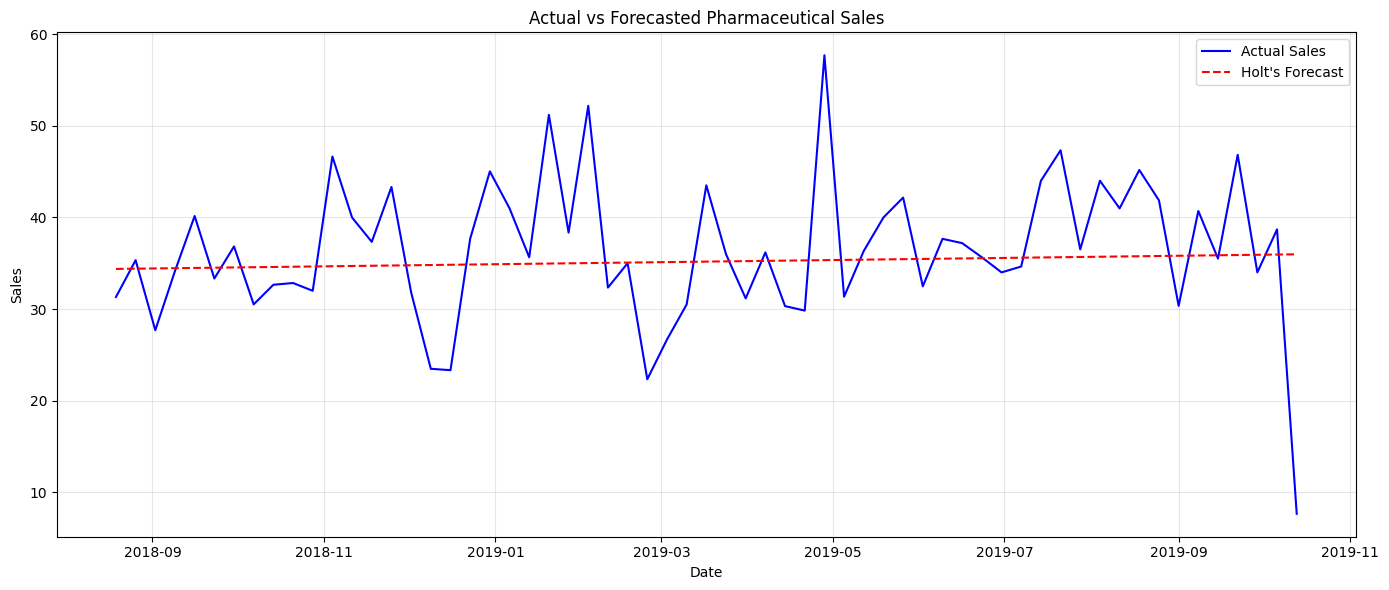

In [83]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Actual sales from the test period
plt.plot(
    test.index,
    test["sales"],
    label="Actual Sales",
    color="blue"
)

# Holt's forecast
plt.plot(
    hw_forecast.index,
    hw_forecast,
    label="Holt's Forecast",
    color="red",
    linestyle="--"
)

plt.title("Actual vs Forecasted Pharmaceutical Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [84]:

# Step 22: Seasonal Naive Forecast

# Repeat sales from 52 weeks earlier
seasonal_period = 52

# Use the last 52 weeks of training sales as the repeating pattern
last_season = train["sales"].iloc[-seasonal_period:]

# Repeat that pattern to cover the test period
seasonal_forecast = pd.Series(
    [last_season.iloc[i % seasonal_period]
     for i in range(len(test))],
    index=test.index,
    name="Seasonal Naive Forecast"
)

# Display the first five predictions
print("First five seasonal forecast predictions:")
print(seasonal_forecast.head())


First five seasonal forecast predictions:
datum
2018-08-19    35.82
2018-08-26    40.65
2018-09-02    55.86
2018-09-09    38.17
2018-09-16    27.00
Name: Seasonal Naive Forecast, dtype: float64


In [85]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate forecasting errors
seasonal_mae = mean_absolute_error(
    test["sales"], seasonal_forecast
)

seasonal_rmse = np.sqrt(
    mean_squared_error(test["sales"], seasonal_forecast)
)

print("Seasonal Naive Forecast Evaluation")
print("----------------------------------")
print("MAE:", round(seasonal_mae, 2))
print("RMSE:", round(seasonal_rmse, 2))


Seasonal Naive Forecast Evaluation
----------------------------------
MAE: 8.81
RMSE: 11.07


In [86]:
# Step 23: Compare forecasting models

results = pd.DataFrame({
    "Model": [
        "Naive Forecast",
        "Holt's Exponential Smoothing",
        "Seasonal Naive Forecast"
    ],
    "MAE": [mae, hw_mae, seasonal_mae],
    "RMSE": [rmse, hw_rmse, seasonal_rmse]
})

print(results.sort_values("RMSE").round(2))

                          Model   MAE   RMSE
1  Holt's Exponential Smoothing  5.69   7.88
0                Naive Forecast  6.21   8.13
2       Seasonal Naive Forecast  8.81  11.07


In [87]:

# Step 24: SARIMA Forecasting

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Train the SARIMA model using training data
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit the model
sarima_fit = sarima_model.fit(disp=False)

# Forecast the test period
sarima_forecast = sarima_fit.forecast(steps=len(test))

# Match forecast dates with test dates
sarima_forecast.index = test.index

# Display the first five predictions
print("First five SARIMA predictions:")
print(sarima_forecast.head())


C:\Users\harsh\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
C:\Users\harsh\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
C:\Users\harsh\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


First five SARIMA predictions:
datum
2018-08-19    36.190759
2018-08-26    39.005866
2018-09-02    52.258009
2018-09-09    35.242596
2018-09-16    28.180740
Name: predicted_mean, dtype: float64


In [88]:

# Step 25: Evaluate SARIMA Forecasting

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
sarima_mae = mean_absolute_error(
    test["sales"], sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(test["sales"], sarima_forecast)
)

print("SARIMA MAE:", round(sarima_mae, 2))
print("SARIMA RMSE:", round(sarima_rmse, 2))


SARIMA MAE: 8.31
SARIMA RMSE: 10.18


In [89]:

# Step 26: Compare Forecasting Models

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Naive Forecast",
        "Holt's Exponential Smoothing",
        "Seasonal Naive Forecast",
        "SARIMA"
    ],
    "MAE": [
        6.21,
        5.69,
        8.81,
        sarima_mae
    ],
    "RMSE": [
        8.13,
        7.88,
        11.07,
        sarima_rmse
    ]
})

results = results.sort_values("MAE").reset_index(drop=True)

print("Forecasting Model Comparison:")
display(results)


Forecasting Model Comparison:


,Model,MAE,RMSE
0,Holt's Exponential Smoothing,5.690000,7.88000
1,Naive Forecast,6.210000,8.13000
2,SARIMA,8.308116,10.17978
3,Seasonal Naive Forecast,8.810000,11.07000


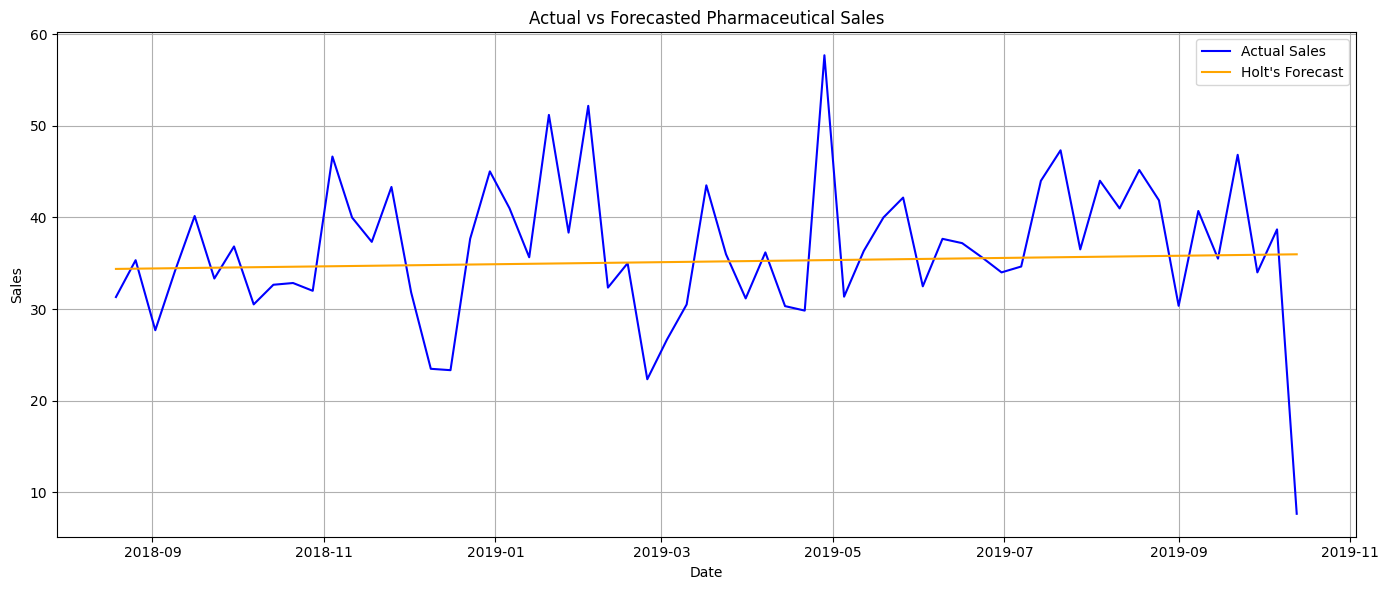

In [90]:

# Step 27: Actual vs Predicted Sales

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test["sales"],
    label="Actual Sales",
    color="blue"
)

plt.plot(
    test.index,
    hw_forecast,
    label="Holt's Forecast",
    color="orange"
)

plt.title("Actual vs Forecasted Pharmaceutical Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


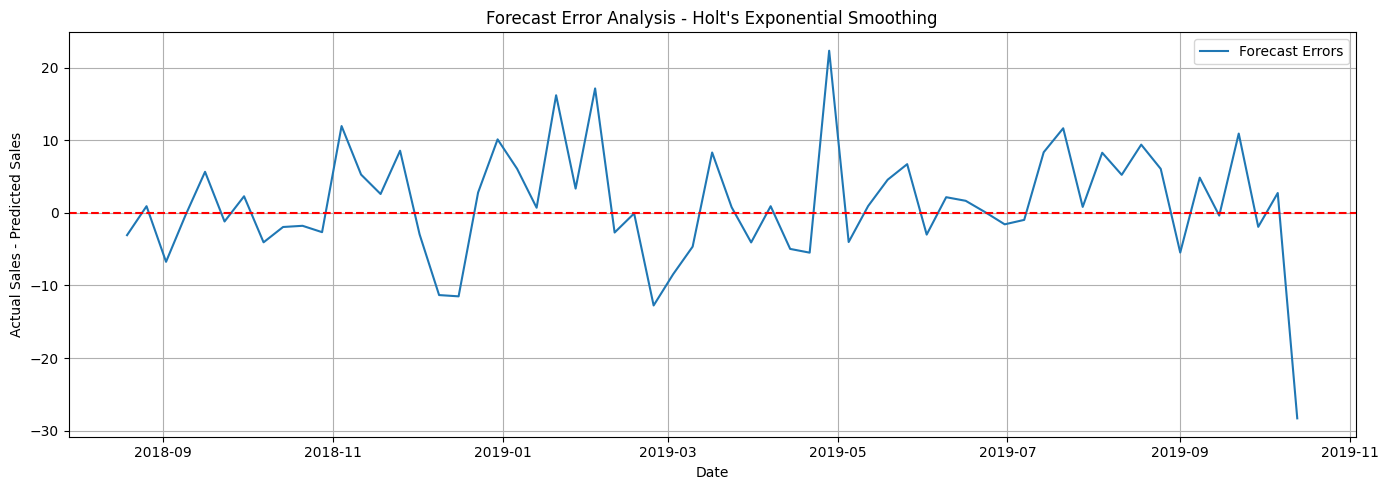

Mean Forecast Error: 1.22
Mean Absolute Error: 5.69


In [91]:

# Step 28: Forecast Error Analysis

import matplotlib.pyplot as plt

# Calculate forecast errors
residuals = test["sales"] - hw_forecast

# Plot forecast errors
plt.figure(figsize=(14, 5))
plt.plot(test.index, residuals, label="Forecast Errors")
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Forecast Error Analysis - Holt's Exponential Smoothing")
plt.xlabel("Date")
plt.ylabel("Actual Sales - Predicted Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Mean Forecast Error:", round(residuals.mean(), 2))
print("Mean Absolute Error:", round(residuals.abs().mean(), 2))


In [92]:

# Step 29: Forecast Future Pharmaceutical Sales

# Train Holt's model on all available sales data
final_hw_model = ExponentialSmoothing(
    df["M01AB"],
    trend="add",
    seasonal=None,
    initialization_method="estimated"
).fit()

# Forecast the next 12 weeks
future_forecast = final_hw_model.forecast(12)

# Display forecasted sales
print("Future Sales Forecast (Next 12 Weeks):")
display(future_forecast)


Future Sales Forecast (Next 12 Weeks):


302    36.381331
303    36.409308
304    36.437284
305    36.465261
306    36.493238
307    36.521214
308    36.549191
309    36.577168
310    36.605145
311    36.633121
312    36.661098
313    36.689075
dtype: float64

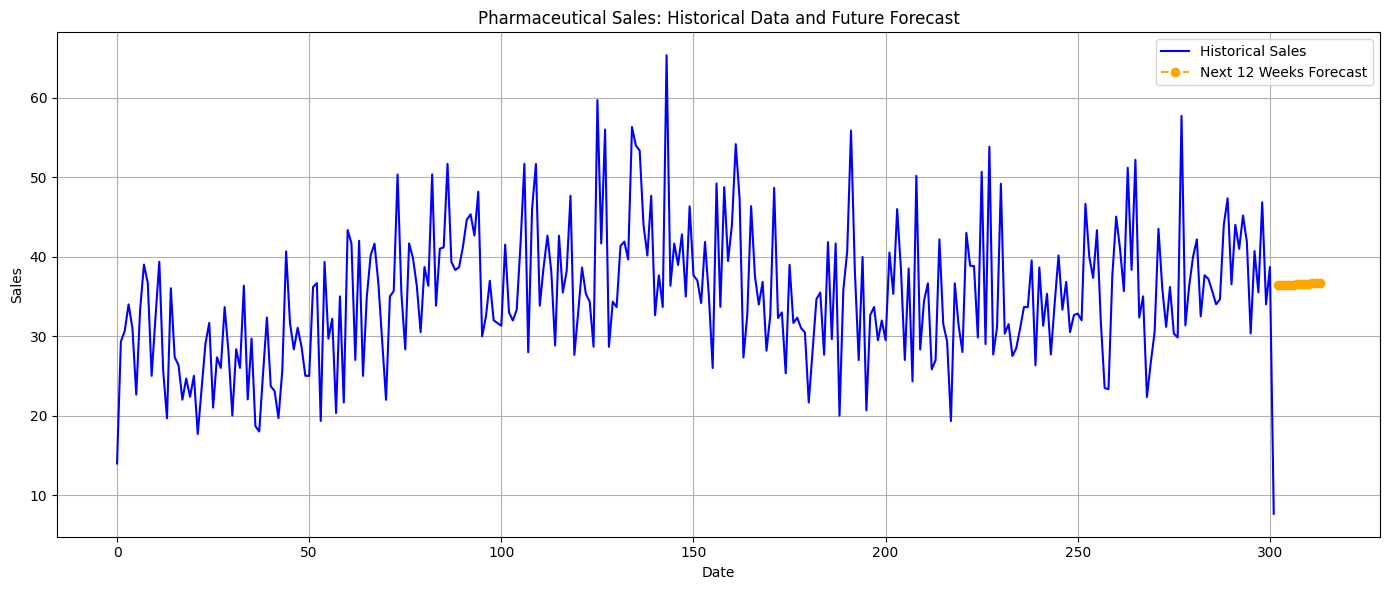

In [93]:

# Step 30: Plot Historical Sales and Future Forecast

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Historical sales
plt.plot(
    df.index,
    df["M01AB"],
    label="Historical Sales",
    color="blue"
)

# Future forecast
plt.plot(
    future_forecast.index,
    future_forecast,
    label="Next 12 Weeks Forecast",
    color="orange",
    linestyle="--",
    marker="o"
)

plt.title("Pharmaceutical Sales: Historical Data and Future Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [94]:

# Step 31: Save Future Forecast to CSV

forecast_df = future_forecast.reset_index()

forecast_df.columns = ["Date", "Predicted_Sales"]

forecast_df.to_csv(
    "pharmaceutical_sales_forecast.csv",
    index=False
)

print("Forecast saved successfully!")
display(forecast_df)


Forecast saved successfully!


,Date,Predicted_Sales
0,302,36.381331
1,303,36.409308
2,304,36.437284
3,305,36.465261
4,306,36.493238
5,307,36.521214
6,308,36.549191
7,309,36.577168
8,310,36.605145
9,311,36.633121


# Pharmaceutical Sales Forecasting — Conclusion

## Project Overview
This project uses historical pharmaceutical sales data to analyze weekly sales patterns and forecast future product demand.

## Models Implemented
1. Naive Forecast
2. Holt's Exponential Smoothing
3. Seasonal Naive Forecast
4. SARIMA

## Model Evaluation

The models were evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

| Model | MAE | RMSE |
|---|---:|---:|
| Holt's Exponential Smoothing | 5.69 | 7.88 |
| Naive Forecast | 6.21 | 8.13 |
| Seasonal Naive Forecast | 8.81 | 11.07 |
| SARIMA | 8.31 | 10.18 |

Holt's Exponential Smoothing achieved the lowest MAE and RMSE among the four models tested. Therefore, it was the best-performing model for the selected test period.

## Business Insights
- Sales forecasting can support pharmaceutical inventory planning and demand management.
- Forecasts can help identify expected sales levels and support replenishment decisions.
- Forecast accuracy should be monitored as new sales data becomes available.

## Limitations
- The analysis focuses on a selected pharmaceutical product.
- The models may not capture every sales fluctuation or external factor.
- Future forecasts are estimates, not guaranteed outcomes.

## Future Improvements
- Evaluate additional forecasting models.
- Analyze multiple pharmaceutical products.
- Incorporate promotions, holidays, and other relevant factors.
- Retrain and evaluate models as new data becomes available.

## Final Conclusion
The project demonstrates a time-series forecasting workflow, from historical sales analysis and model development to evaluation and future demand prediction. Holt's Exponential Smoothing performed best among the models evaluated on the selected test dataset.
